# Clase 02 (versión condensada) — K-means y DBSCAN con scikit-learn

> **Pregunta de negocio:** ¿Qué tipos de clientes tenemos y cuáles no encajan
> en ninguno?

La directora de marketing ha visto la tabla de la clase 1 (5 852 clientes de
un comercio online británico, con su recencia, frecuencia, gasto, productos
distintos y devoluciones a fecha 2011-12-10) y pide dos cosas:

> "Necesito unos pocos grupos, cuatro o cinco, que pueda explicar a mi equipo.
> Y quiero saber qué clientes no encajan en ninguno."

La primera es una **segmentación** y la resolveremos con **K-means**; la
segunda, una **detección de atípicos**, con **DBSCAN**. Los dos algoritmos
están ya programados en la librería **scikit-learn**: no vamos a programarlos,
sino a aprender a **usarlos bien**: qué hay que darles, qué parámetros
importan, dónde quedan los resultados y cómo se leen.

Este notebook es una **versión condensada** del notebook completo de la
clase (`clase_02.ipynb`): menos teoría estadística y más práctica con las
librerías. Si quieres ver cómo funcionan los algoritmos por dentro, ve al
notebook completo o al capítulo de teoría de la clase 2.

### Antes de empezar: qué necesitas

1. **Python 3 con Jupyter** y las librerías `pandas`, `numpy`, `matplotlib`,
   `scikit-learn` y `pyarrow` (sirve para leer los ficheros `.parquet`). Si
   te falta alguna, instálala desde una celda con `%pip install scikit-learn`
   (cambiando el nombre por el de la que falte) y reinicia el kernel.
2. **Dos ficheros de datos**, que te dará el profesor, copiados en **la misma
   carpeta que este notebook** y sin cambiarles el nombre:

| Fichero | Para qué sirve |
| --- | --- |
| `customers.parquet` | La tabla de cliente de la clase 1: el punto de partida |
| `customers_segments_referencia.parquet` | La tabla de segmentos de referencia: celdas de rescate y comprobar la tuya |

### Índice

| Parte | Contenido |
| --- | --- |
| 0 | Configuración |
| 1 | El patrón de scikit-learn: crear, ajustar, leer |
| 2 | Preparar los datos: `StandardScaler` (ejercicio 1) |
| 3 | `KMeans`: elegir K y ajustar (ejercicios 2 y 3) |
| 4 | `DBSCAN`: elegir `eps` y encontrar atípicos (ejercicios 4 y 5) |
| 5 | Del modelo al caso: mapa y tabla de segmentos (ejercicio 6) |
| 6 | Chuleta y síntesis |

### Cómo trabajar con este notebook

- Cada parte empieza con una **explicación** y un **ejemplo resuelto** con
  pocos clientes de juguete: léelos y ejecútalos antes de los ejercicios.
- Las celdas de ejercicio tienen huecos `COMPLETA` con un comentario
  `# TODO:` que dice qué falta. Si ves `NameError: name 'COMPLETA' is not
  defined`, te falta rellenar un hueco.
- Tras cada ejercicio de código hay una **celda de comprobación**: si
  imprime `✔ Correcto`, vas bien; si no, su mensaje te orienta.
- Las **celdas de rescate** cargan un resultado ya preparado para que puedas
  seguir si te has atascado: cambia `USAR_RESCATE = False` por `True` y
  ejecútala.
- Las celdas **Tu respuesta** son para escribir tus conclusiones.
- Fijamos siempre la semilla (`random_state=SEMILLA`) para que obtengas las
  mismas cifras que el texto.

## 0. Configuración

Importamos las librerías, comprobamos que los ficheros están en esta carpeta
y fijamos la semilla y el estilo de las figuras. También definimos
`perfilar`, una función que usaremos en las partes 3 y 5 para describir los
grupos (se explica allí).

In [30]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow  # no se usa directamente: pandas la necesita para leer los .parquet
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Los ficheros de datos tienen que estar en la misma carpeta que este notebook.
FICHEROS_CLASE = ["customers.parquet", "customers_segments_referencia.parquet"]
faltan = [fichero for fichero in FICHEROS_CLASE if not Path(fichero).exists()]
if faltan:
    raise FileNotFoundError(f"Faltan estos ficheros en la carpeta {Path.cwd()}: {faltan}. "
                            "Cópialos a mano junto al notebook, sin cambiarles el nombre. "
                            "Si ya están, abre el notebook desde su propia carpeta.")

# Aquí se guarda tu entregable.
DIR_SALIDAS = Path("salidas")
DIR_SALIDAS.mkdir(exist_ok=True)

# Semilla de todo lo que usa números al azar: así todos obtenemos las mismas cifras.
SEMILLA = 42

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
COLORES = [AZUL, NARANJA, AQUA, AMARILLO]   # un color por cluster
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
})


def perfilar(tabla, columna_grupo, variables):
    '''Tamaño, medianas de las variables y % de clientes y de gasto de cada grupo.'''
    perfil = tabla.groupby(columna_grupo)[variables].median()
    perfil.insert(0, "clientes", tabla.groupby(columna_grupo).size())
    perfil["pct_clientes"] = (100 * perfil["clientes"] / perfil["clientes"].sum()).round(1)
    gasto = tabla.groupby(columna_grupo)["monetary"].sum()
    perfil["pct_gasto"] = (100 * gasto / tabla["monetary"].sum()).round(1)
    return perfil


print("✔ Configuración lista")

✔ Configuración lista


## 1. El patrón de scikit-learn: crear, ajustar, leer

Todos los modelos de scikit-learn se usan igual, sean de clustering, de
clasificación o de regresión. Aprender este patrón una vez sirve para el
resto del curso:

| Paso | Código | Qué hace |
| --- | --- | --- |
| 1. Crear | `modelo = KMeans(n_clusters=2)` | Crea el objeto con sus **hiperparámetros** (las decisiones que tomas tú). Todavía no ha visto datos. |
| 2. Ajustar | `modelo.fit(X)` | El algoritmo aprende de los datos `X`. |
| 3. Leer | `modelo.labels_`, `modelo.inertia_`... | Los resultados quedan en **atributos que acaban en guion bajo**: solo existen después de `fit`. |
| 3 bis. Usar | `modelo.predict(X_nuevo)` | Aplica lo aprendido a datos nuevos (no todos los modelos lo tienen). |

Dos atajos muy habituales: `modelo.fit_predict(X)` ajusta y devuelve las
etiquetas en una sola línea, y `modelo.fit_transform(X)` ajusta y devuelve
los datos transformados.

**Qué espera scikit-learn en `X`:** una tabla o matriz **numérica, sin
nulos**, con una **fila por observación** (aquí, por cliente) y una
**columna por variable**. Puede ser un `DataFrame` de pandas o una matriz de
NumPy.

**Ejemplo resuelto: seis clientes.** Número de compras y gasto en cientos de
libras. A la vista hay dos grupos: A, B y C compran poco y gastan poco; D, E
y F compran a menudo y gastan mucho. Le pedimos a K-means que encuentre dos
grupos.

In [31]:
puntos_ejemplo = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [1.5, 2.0, 1.0, 12.0, 15.0, 10.0],   # gasto en cientos de libras
}, index=list("ABCDEF"))

# 1. Crear: solo guarda los hiperparámetros.
modelo_ejemplo = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA)
print("Antes de fit:", modelo_ejemplo)

# 2. Ajustar.
modelo_ejemplo.fit(puntos_ejemplo)

# 3. Leer los resultados.
print("labels_ (grupo de cada cliente):", dict(zip(puntos_ejemplo.index, modelo_ejemplo.labels_.tolist())))
print("cluster_centers_ (centro de cada grupo):")
print(modelo_ejemplo.cluster_centers_.round(2))
print(f"inertia_ (suma de distancias al cuadrado a su centro): {modelo_ejemplo.inertia_:.2f}")

Antes de fit: KMeans(n_clusters=2, n_init=10, random_state=42)
labels_ (grupo de cada cliente): {'A': 0, 'B': 0, 'C': 0, 'D': 1, 'E': 1, 'F': 1}
cluster_centers_ (centro de cada grupo):
[[ 2.    1.5 ]
 [10.33 12.33]]
inertia_ (suma de distancias al cuadrado a su centro): 19.83


Cómo se lee:

- `labels_` tiene **un número por cliente**, en el mismo orden que las filas
  de `X`: A, B y C están en el grupo 0; D, E y F, en el 1. Los números son
  **etiquetas arbitrarias**: con otra semilla podrían salir al revés, y no
  significaría nada distinto.
- `cluster_centers_` tiene **una fila por grupo y una columna por variable**:
  el centro del grupo 0 es (2 compras; 1,5 cientos de libras), la media de
  A, B y C.
- `inertia_` resume lo compactos que son los grupos: cuanto más baja, más
  cerca está cada cliente de su centro.

Con el modelo ya ajustado, `predict` asigna clientes nuevos al grupo cuyo
centro está más cerca. Y `fit_predict` hace `fit` y devuelve `labels_` de una
vez:

In [32]:
cliente_nuevo = pd.DataFrame({"frequency": [4], "monetary": [3.0]})
print("Grupo del cliente nuevo:", modelo_ejemplo.predict(cliente_nuevo))

# puntos_ejemplo = pd.concat([puntos_ejemplo, cliente_nuevo]) # Ejecutar una vez

etiquetas_ejemplo = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA).fit_predict(puntos_ejemplo)
print("fit_predict:", etiquetas_ejemplo)

Grupo del cliente nuevo: [0]
fit_predict: [0 0 0 1 1 1]


**Cómo consultar la ayuda.** No hace falta memorizar los parámetros:

- `help(KMeans)` o `KMeans?` en una celda muestran la documentación: los
  parámetros (*Parameters*), los atributos (*Attributes*) y los métodos.
- `modelo.get_params()` lista los hiperparámetros con los que se creó un
  modelo, incluidos los que se quedaron con su valor por defecto.
- La documentación en línea (scikit-learn.org, buscando el nombre de la
  clase) tiene además ejemplos.

Si intentas leer `modelo.labels_` antes de `fit`, Python da un
`AttributeError`: el atributo todavía no existe.

In [33]:
parametros = modelo_ejemplo.get_params()
print({nombre: parametros[nombre] for nombre in ["n_clusters", "n_init", "init", "max_iter", "random_state"]})

{'n_clusters': 2, 'n_init': 10, 'init': 'k-means++', 'max_iter': 300, 'random_state': 42}


k-means++ es una mejor forma de poner los centroides para kmeans

max_iter son las iteraciones que se hacen en k-means, porque podía acabar o cuando los centroides ya no se muevan o cuando se lleguen a max_iter

## 2. Preparar los datos: `StandardScaler`

K-means y DBSCAN agrupan a los clientes según la **distancia** entre ellos.
La distancia mezcla todas las variables, así que una variable con números
grandes (el gasto, en miles de libras) domina sobre una con números pequeños
(las compras, de 1 a 10). Antes de agrupar hay que poner todas las variables
en la misma escala. Dos herramientas:

- **`np.log1p(tabla)`** calcula log(1 + x) de cada valor (vale también con
  ceros). Sirve con variables muy asimétricas, como el gasto: unos pocos
  clientes gastan cientos de veces más que el resto, y el logaritmo hace que
  se comparen diferencias relativas ("el doble") en lugar de absolutas.
- **`StandardScaler`** estandariza cada columna: le resta su media y la
  divide por su desviación típica. Después, todas las columnas tienen media
  0 y desviación 1: un 1 significa "una desviación por encima de la media",
  sea en compras o en libras.

`StandardScaler` sigue el mismo patrón que un modelo: se crea, se ajusta
(`fit` calcula la media y la desviación de cada columna, que quedan en
`mean_` y `scale_`) y se aplica (`transform`). `fit_transform` hace las dos
cosas de una vez.

**Ejemplo resuelto:** los seis clientes, ahora con el gasto en libras.

In [34]:
seis_ejemplo = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [150, 200, 100, 1200, 1500, 1000],   # gasto en libras
}, index=list("ABCDEF"))

escalador_ejemplo = StandardScaler()
seis_escalados = escalador_ejemplo.fit_transform(seis_ejemplo) 
# No es fit_predict es fit_transform por que no queremos nuevas etiquetas queremos escalar las que ya tenemos

print("Medias aprendidas (mean_):", escalador_ejemplo.mean_.round(2))
print("Desviaciones aprendidas (scale_):", escalador_ejemplo.scale_.round(2))
print(type(seis_escalados))   # ¡ya no es una tabla de pandas, sino una matriz de NumPy!
seis_escalados = pd.DataFrame(seis_escalados, columns=seis_ejemplo.columns, index=seis_ejemplo.index)
print(seis_escalados.round(2))

# np.linalg.norm(a - b) es la distancia en línea recta entre dos clientes.
for nombre, tabla in [("sin escalar", seis_ejemplo), ("escalados", seis_escalados)]:
    a, b, d = tabla.loc["A"], tabla.loc["B"], tabla.loc["D"]
    print(f"{nombre:12s} A-B = {np.linalg.norm(a - b):8.2f}   A-D = {np.linalg.norm(a - d):8.2f}")

Medias aprendidas (mean_): [  6.17 691.67]
Desviaciones aprendidas (scale_): [  4.3  561.56]
<class 'numpy.ndarray'>
   frequency  monetary
A      -0.97     -0.96
B      -0.74     -0.88
C      -1.20     -1.05
D       0.89      0.91
E       1.36      1.44
F       0.66      0.55
sin escalar  A-B =    50.01   A-D =  1050.03
escalados    A-B =     0.25   A-D =     2.64


Sin escalar, la distancia A–B (50,01) es casi exactamente su diferencia de
gasto (50 libras) y la A–D (1 050,03), la suya (1 050 libras): las compras
no cuentan. Escalados, las dos variables pesan lo mismo: D está 0,89
desviaciones por encima de la media en compras y 0,91 en gasto.

Y así actúa `log1p`: cada vez que un valor se multiplica por 10, su
logaritmo solo suma 2,3. Un cliente que gasta 10 000 libras queda a la misma
distancia de uno de 1 000 que este de uno de 100:

In [35]:
print(np.log1p([0, 9, 99, 999, 9999]).round(2))   # log(1 + x) de 0, 9, 99, 999 y 9 999

[0.   2.3  4.61 6.91 9.21]


Fíjate en dos detalles que causan muchos errores:

- `fit_transform` **devuelve una matriz de NumPy**, sin nombres de columnas
  ni índice. El orden de las filas es el mismo que el de la tabla original,
  así que los resultados se pueden volver a pegar a la tabla.
- El escalador **recuerda** la media y la desviación. Para escalar un cliente
  nuevo se usa `escalador.transform(nuevo)`, **no** `fit_transform`: el
  cliente nuevo tiene que medirse con la misma regla que los demás. Y
  `escalador.inverse_transform(...)` deshace el escalado, para volver a
  leer en unidades originales (lo usaremos en la parte 3).

*Para saber más: notebook completo, B1; capítulo de la clase 2, apartados 02.3.1 a 02.3.3.*

### Ejercicio 1 · Preparar la matriz de clientes · completar código + interpretar

Construye `X`, la matriz con la que trabajarán K-means y DBSCAN: 5 852 filas
(clientes) y 4 columnas (las variables de comportamiento), con logaritmo y
después estandarización. Guarda el escalador en `escalador`: lo necesitarás
para leer los centros de K-means.

In [36]:
# TU CÓDIGO
customers = pd.read_parquet("customers.parquet")
# print(customers)

VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
# X_log = np.log1p([customers.recency_days, customers.frequency, customers.monetary, customers.n_products]) # Es otra forma

# customers = customers[VARIABLES]
X_log = np.log1p(customers[VARIABLES])  # TODO: logaritmo log(1 + x) de las cuatro variables
# print(X_log)
escalador = StandardScaler()  # TODO: crea el escalador
X = escalador.fit_transform(X_log)  # TODO: ajusta el escalador y transforma X_log

print("Forma de X:", X.shape)
print("Media de cada columna:", X.mean(axis=0).round(2) + 0.0)   # + 0.0 evita que se imprima "-0."
print("Desviación de cada columna:", X.std(axis=0).round(2))

Forma de X: (5852, 4)
Media de cada columna: [0. 0. 0. 0.]
Desviación de cada columna: [1. 1. 1. 1.]


In [37]:
# Comprobación
assert X.shape == (5852, 4), "X debe tener 5 852 filas y 4 columnas: usa customers[VARIABLES]."
assert np.allclose(X.mean(axis=0), 0) and np.allclose(X.std(axis=0), 1), \
    "Las columnas de X deben tener media 0 y desviación 1: ¿has usado fit_transform?"
assert round(X[0, 2], 4) == 3.2215, "Revisa el orden: primero log1p y después StandardScaler."
print("✔ Correcto")

✔ Correcto


**Pregunta de examen:** Si tenemos unos datos con cola larga o sea una distribución ASIMÉTRICA, primero hay que normalizarlo con LOG para que quede en campana de Gauss y luego ya aplicar la estandarización.

No podemos aplicar el estandarizado sobre ASIMÉTRICAS directamente.

Pregunta: ¿qué significa que el primer cliente tenga un 3,22 en la columna
del gasto? ¿Por qué no podemos agrupar directamente con
`customers[VARIABLES]`?

**Tu respuesta:**

## 3. `KMeans`: elegir K y ajustar

Si te has atascado antes, activa la celda de rescate: crea `customers`,
`VARIABLES`, `escalador` y `X`.

In [38]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    escalador = StandardScaler()
    X = escalador.fit_transform(np.log1p(customers[VARIABLES]))
    print("Rescate cargado: X de", X.shape)

**Qué hace K-means, en una línea:** coloca K centros, asigna cada cliente al
centro más cercano, mueve cada centro a la media de sus clientes y repite
hasta que nada cambia. Resultado: K grupos, cada uno con su centro.

**Los parámetros que importan:**

| Parámetro | Qué es | Qué ponemos |
| --- | --- | --- |
| `n_clusters` | Cuántos grupos (la K) | Lo decides tú: ver abajo |
| `n_init` | Cuántas veces repite el algoritmo desde centros iniciales distintos; se queda con la de menor inercia | `10`: el resultado depende del arranque, y repetir evita quedarse con uno malo |
| `random_state` | Semilla de los centros iniciales | `SEMILLA`, para que el resultado sea reproducible |
| `init`, `max_iter` | Cómo se eligen los centros iniciales y cuántas vueltas como máximo | Los valores por defecto (`"k-means++"`, 300) van bien |

**Los resultados**, después de `fit`:

| Atributo / método | Qué contiene |
| --- | --- |
| `labels_` | El grupo de cada fila de `X` (0, 1, ..., K−1) |
| `cluster_centers_` | Los K centros, **en la escala de `X`** (aquí, estandarizada) |
| `inertia_` | Suma de las distancias al cuadrado de cada punto a su centro |
| `predict(X_nuevo)` | Asigna filas nuevas al centro más cercano (escaladas con el mismo escalador) |

**K-means no elige K: la eliges tú.** Dos herramientas ayudan:

- **Inercia (`inertia_`) y método del codo.** La inercia siempre baja al
  subir K (con un grupo por cliente sería 0). Se busca el "codo": la K a
  partir de la cual añadir un grupo apenas mejora.
- **Silhouette (`silhouette_score(X, etiquetas)`).** Es una **función**, no
  un modelo: recibe los datos y las etiquetas y devuelve un número entre −1 y
  1. Cerca de 1: cada cliente está mucho más cerca de su grupo que del grupo
  vecino. Cerca de 0: los grupos se tocan. Más alto es mejor. Como
  orientación: por encima de 0,5, grupos bien separados; entre 0,25 y 0,5,
  grupos reales pero que se tocan en los bordes; por debajo de 0,25, poca
  estructura.

Ninguna de las dos decide sola: acotan las K razonables y, entre ellas, se
elige la que tenga más sentido para el negocio (grupos útiles y de un tamaño
manejable).

**Ejemplo resuelto:** inercia y silhouette de los seis clientes con K = 2, 3
y 4.

In [39]:
for k in [2, 3, 4]:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(puntos_ejemplo)
    s = silhouette_score(puntos_ejemplo, modelo.labels_)
    print(f"K = {k}: inercia = {modelo.inertia_:6.2f}   silhouette = {s:.3f}")

K = 2: inercia =  19.83   silhouette = 0.801
K = 3: inercia =   5.00   silhouette = 0.604
K = 4: inercia =   2.50   silhouette = 0.432


La inercia baja siempre (19,83 → 5,00 → 2,50), pero la silhouette es máxima
con K = 2 (0,801): partir los grupos naturales en trozos los hace más
compactos, pero menos separados entre sí. Con los datos reales, la decisión
no será tan clara.

*Para saber más: notebook completo, B2 (incluye K-means programado a mano y
la estabilidad entre semillas); capítulo de la clase 2, apartados 02.4.1 a
02.4.3.*

**Pregunta de examen:** El threshold de Silhouette estaría en en 0.3 como norma general. Los silhouettes que sean < 0.3 se descartan.

### Ejercicio 2 · Elegir K · completar código + interpretar

Calcula la inercia y la silhouette de K-means para K entre 2 y 8 sobre los
5 852 clientes. La columna `cluster_menor` (dada) cuenta los clientes del
grupo más pequeño. La celda tarda unos segundos.

In [40]:
# TU CÓDIGO
filas = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)  # TODO: K-means con k grupos, 10 arranques y la semilla, ajustado a X
    inercia = modelo.inertia_  # TODO: inercia del modelo
    silhouette = silhouette_score(X, modelo.labels_)  # TODO: silhouette de las etiquetas del modelo
    filas.append({"k": k, "inercia": inercia, "silhouette": silhouette,
                  # bincount cuenta cuántos clientes hay en cada cluster
                  "cluster_menor": np.bincount(modelo.labels_).min()})
eleccion_k = pd.DataFrame(filas).set_index("k")
eleccion_k.round(3)

,inercia,silhouette,cluster_menor
k,,,
2,"11,936.32",0.41,2453
3,"9,065.36",0.31,1276
4,"7,582.33",0.31,1235
5,"6,578.85",0.28,561
6,"5,891.10",0.26,523
7,"5,319.26",0.26,455
8,"4,944.28",0.24,285


In [41]:
# Comprobación
assert round(eleccion_k.loc[4, "silhouette"], 3) == 0.310, \
    "La silhouette de K = 4 no cuadra: usa silhouette_score(X, modelo.labels_)."
assert round(eleccion_k.loc[4, "inercia"]) == 7582, \
    "La inercia de K = 4 no cuadra: ¿has usado n_init=10 y random_state=SEMILLA?"
print("✔ Correcto")

✔ Correcto


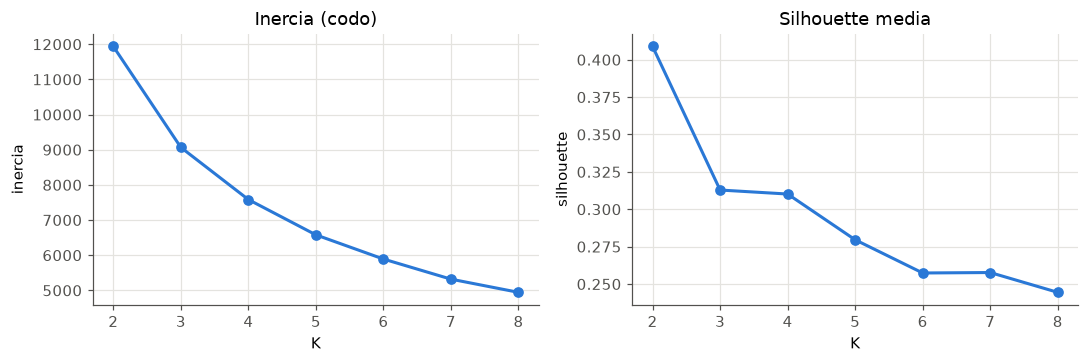

In [42]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(eleccion_k.index, eleccion_k["inercia"], marker="o", color=AZUL, linewidth=2)
axes[0].set(title="Inercia (codo)", xlabel="K", ylabel="inercia")
axes[1].plot(eleccion_k.index, eleccion_k["silhouette"], marker="o", color=AZUL, linewidth=2)
axes[1].set(title="Silhouette media", xlabel="K", ylabel="silhouette")
fig.tight_layout()
plt.show()

Pregunta: ¿qué K elegirías y por qué? ¿Por qué no K = 2, si tiene la
silhouette más alta?

**Tu respuesta:**

### Ejercicio 3 · Ajustar K-means con K = 4 · completar código + interpretar

(a) Ajusta K-means con K = 4 (10 arranques y `random_state=SEMILLA`) y
guarda la etiqueta de cada cliente en `customers["cluster"]`. Como `X` tiene
las filas en el mismo orden que `customers`, `labels_` se puede pegar
directamente como columna.

In [43]:
# TU CÓDIGO
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X)  # TODO: K-means con K grupos, 10 arranques y la semilla
customers["cluster"] = kmeans.labels_  # TODO: etiqueta de cada cliente
# bincount cuenta cuántos clientes tienen la etiqueta 0, 1, 2 y 3.
print("Clientes por cluster:", np.bincount(customers["cluster"])) # bincount cuenta cuántos hay de cada cluster

Clientes por cluster: [1235 1511 1267 1839]


In [44]:
# Comprobación
assert np.bincount(customers["cluster"]).tolist() == [1235, 1511, 1267, 1839], \
    "Los tamaños no cuadran: ¿has usado n_init=10 y random_state=SEMILLA sobre X?"
print("✔ Correcto")

✔ Correcto


In [45]:
# Celda de rescate: cambia False por True solo si no has resuelto el apartado (a).
USAR_RESCATE = False
if USAR_RESCATE:
    kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit(X)
    customers["cluster"] = kmeans.labels_
    print("Rescate cargado: kmeans y customers['cluster']")

(b) Los centros de `cluster_centers_` están en la escala estandarizada, que
no se puede leer ("−0,8 desviaciones de recencia"). Para volver a unidades
originales se deshacen los dos pasos **en orden inverso**:
`escalador.inverse_transform` deshace la estandarización y `np.expm1`
deshace `log1p`. La celda está dada:

In [46]:
centros = pd.DataFrame(kmeans.cluster_centers_, columns=VARIABLES)
print("Centros en la escala de X:")
print(centros.round(2))

centros_originales = pd.DataFrame(np.expm1(escalador.inverse_transform(kmeans.cluster_centers_)),
                                  columns=VARIABLES)
print("\nCentros en unidades originales (días, facturas, libras, productos):")
print(centros_originales.round(1))

Centros en la escala de X:
   recency_days  frequency  monetary  n_products
0         -0.90      -0.17     -0.10       -0.01
1          0.61       0.01      0.22        0.28
2         -0.99       1.45      1.29        1.13
3          0.78      -0.89     -1.01       -1.01

Centros en unidades originales (días, facturas, libras, productos):
   recency_days  frequency  monetary  n_products
0         21.10       3.10    787.60       41.90
1        220.30       3.70  1,226.10       60.10
2         18.20      14.20  5,407.40      169.60
3        288.60       1.30    224.20       11.80


Para describir cada grupo a marketing es más robusto usar **medianas** (unos
pocos mayoristas moverían una media) y añadir su **tamaño** y su **peso en el
gasto**. La función `perfilar`, definida en la configuración, lo hace para
cualquier tabla y columna de grupo: agrupa con `groupby`, calcula la mediana
de cada variable, cuenta los clientes de cada grupo y añade sus porcentajes
de clientes y de gasto. La usaremos también en la parte 5.

Las medianas no coinciden con los centros de arriba (en el cluster 2, 4 623
libras frente a 5 407): el centro es una media calculada en la escala
logarítmica, y la mediana, el valor del cliente del medio. Las dos describen
al cliente "típico" del grupo; para comunicar, usamos la mediana.

In [47]:
perfilar(customers, "cluster", VARIABLES)

,clientes,recency_days,frequency,monetary,n_products,pct_clientes,pct_gasto
cluster,,,,,,,
0,1235,24.00,3.00,806.72,45.00,21.10,8.20
1,1511,241.00,4.00,"1,176.19",60.00,25.80,14.70
2,1267,20.00,12.00,"4,623.28",174.00,21.70,73.90
3,1839,393.00,1.00,237.36,14.00,31.40,3.20


Pregunta: describe cada cluster en una frase con sus cifras. ¿Qué grupo
dirías que es "el negocio"?

**Tu respuesta:**

## 4. `DBSCAN`: elegir `eps` y encontrar atípicos

Si te has atascado antes, activa la celda de rescate: crea `customers` con
la columna `cluster`, `VARIABLES`, `escalador` y `X`.

In [48]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    escalador = StandardScaler()
    X = escalador.fit_transform(np.log1p(customers[VARIABLES]))
    customers["cluster"] = pd.read_parquet("customers_segments_referencia.parquet")["cluster"]
    print("Rescate cargado: X de", X.shape, "y clusters de referencia")

**Qué hace DBSCAN, en tres líneas:** agrupa por **densidad**. Un punto es
**núcleo** si tiene al menos `min_samples` puntos (contándose a sí mismo) a
una distancia de `eps` o menos. Los núcleos cercanos entre sí, y los puntos
que caen cerca de ellos, forman un grupo. Los puntos que no están cerca de
ningún núcleo son **ruido**: no pertenecen a ningún grupo.

Dos diferencias con K-means que cambian cómo se usa:

- **No se le dice cuántos grupos buscar**: salen los que la densidad dé. A
  cambio, hay que elegir `eps` y `min_samples`.
- **No obliga a todos a estar en un grupo.** K-means mete a todos los
  clientes en algún grupo, por raros que sean; DBSCAN deja fuera a los que
  no se parecen a nadie. Por eso lo usamos para encontrar atípicos.

**Los parámetros:**

| Parámetro | Qué es | Efecto |
| --- | --- | --- |
| `eps` | Radio del vecindario, en la escala de `X` | Más grande: más vecinos, grupos más grandes, menos ruido |
| `min_samples` | Vecinos mínimos (contándose a sí mismo) para ser núcleo | Más grande: más exigente, más ruido |

**Los resultados**, después de `fit`:

| Atributo | Qué contiene |
| --- | --- |
| `labels_` | El grupo de cada fila (0, 1, ...) y **−1 para el ruido** |
| `core_sample_indices_` | Las posiciones de los puntos núcleo |

DBSCAN **no tiene `predict`**: los grupos dependen de los puntos que había al
ajustar, así que no sabe asignar puntos nuevos. Para analizar otros datos, se
vuelve a ajustar.

**Ejemplo resuelto:** los seis clientes de la parte 1 (gasto en cientos de
libras) más un cliente H con 25 compras y 300 libras, que no se parece a
nadie. Como en la parte 1, el gasto va en cientos de libras para que las dos
variables tengan rangos parecidos (un escalado "a mano", suficiente para
siete clientes; con los datos reales usamos `X`). Comparamos DBSCAN
(`eps=4`, `min_samples=3`) con K-means (K = 2).

In [49]:
siete_ejemplo = pd.concat([puntos_ejemplo,
                           pd.DataFrame({"frequency": [25], "monetary": [3.0]}, index=["H"])])

dbscan_ejemplo = DBSCAN(eps=4, min_samples=3).fit(siete_ejemplo)
kmeans_siete = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA).fit(siete_ejemplo)

resultado_ejemplo = siete_ejemplo.copy()
resultado_ejemplo["dbscan"] = dbscan_ejemplo.labels_
resultado_ejemplo["kmeans"] = kmeans_siete.labels_
print("Núcleos de DBSCAN:", siete_ejemplo.index[dbscan_ejemplo.core_sample_indices_].tolist())
resultado_ejemplo

Núcleos de DBSCAN: ['A', 'B', 'C', 'D']


,frequency,monetary,dbscan,kmeans
A,2,1.50,0,1
B,3,2.00,0,1
C,1,1.00,0,1
D,10,12.00,1,0
E,12,15.00,1,0
F,9,10.00,1,0
H,25,3.00,-1,0


DBSCAN encuentra los dos grupos y marca a H como ruido (−1). K-means, en
cambio, mete a H en el grupo de D, E y F, porque siempre asigna a todos.
Además, no todos los miembros de un grupo son núcleo: E y F tienen menos de
3 puntos a distancia 4 o menos, pero están cerca de D, que sí lo es, y por
eso entran en su grupo.

**Cómo elegir `eps`.** No hay una regla automática, pero sí dos
herramientas:

1. **Mirar las distancias a los vecinos.** Con `NearestNeighbors`, otro
   objeto de scikit-learn con el mismo patrón, calculamos la distancia de
   cada cliente a su vecino número `min_samples` (contándose a sí mismo,
   como DBSCAN). Un `eps` por debajo de esa distancia deja al cliente sin
   vecinos suficientes. Sus percentiles dan el rango razonable de `eps`.
2. **Probar varios `eps`** y mirar cuántos grupos y cuánto ruido salen
   (ejercicio 4).

Usaremos `min_samples = 8`, el doble del número de variables: una regla
práctica habitual. La celda de las distancias está dada:

In [50]:
# Prueba

vecinos = NearestNeighbors(n_neighbors=8).fit(X)
resul = vecinos.kneighbors(X)
resul

(array([[0.        , 1.11131919, 1.29601079, ..., 1.70203909, 1.7342723 ,
         1.7757137 ],
        [0.        , 0.19317013, 0.37308671, ..., 0.42817439, 0.42852576,
         0.441303  ],
        [0.        , 0.26848061, 0.27228345, ..., 0.32623054, 0.33058966,
         0.34345946],
        ...,
        [0.        , 0.08648342, 0.08674417, ..., 0.11336791, 0.11572568,
         0.12998522],
        [0.        , 0.06291899, 0.12651867, ..., 0.17015447, 0.17465448,
         0.18705654],
        [0.        , 0.19778092, 0.24396651, ..., 0.28278135, 0.28323574,
         0.28438761]], shape=(5852, 8)),
 array([[   0, 1527, 3351, ..., 1715, 5616, 2638],
        [   1, 5836,  263, ..., 2237, 2163, 1165],
        [   2, 1216, 1065, ..., 3414,  691, 3777],
        ...,
        [5849, 2635, 3785, ..., 5750, 5716, 1642],
        [5850, 4711, 2106, ..., 1011, 2992,  184],
        [5851, 3571, 4662, ..., 2973, 1606,  292]], shape=(5852, 8)))

In [51]:
MIN_SAMPLES = 8 # Es 8 por que son 4 variables x 2 (convención)

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
distancias, posiciones = vecinos.kneighbors(X)   # devuelve dos listas así que separamos en una fila por cliente, una columna por vecino
dist_vecino_8 = distancias[:, -1]                # la última columna: el vecino número 8
for q in [50, 90, 95, 99]:
    print(f"El {q} % de los clientes tiene su vecino 8 a menos de {np.percentile(dist_vecino_8, q):.2f}")

El 50 % de los clientes tiene su vecino 8 a menos de 0.29
El 90 % de los clientes tiene su vecino 8 a menos de 0.52
El 95 % de los clientes tiene su vecino 8 a menos de 0.65
El 99 % de los clientes tiene su vecino 8 a menos de 1.07


La mitad de los clientes tiene 8 vecinos a menos de 0,29; solo el 1 % los
tiene más lejos de 1,07. Los valores razonables de `eps` están entre esos
dos números: con uno menor, demasiados clientes quedarían como ruido; con
uno mayor, casi nadie.

*Para saber más: notebook completo, B4 y B5; capítulo de la clase 2,
apartados 02.5.1 a 02.5.4.*

### Ejercicio 4 · Probar varios `eps` · completar código + interpretar

Para cada `eps` de la lista, ajusta DBSCAN con `min_samples = MIN_SAMPLES` y
cuenta los clusters y los clientes de ruido. Recuerda que los clusters se
numeran desde 0 y el ruido es −1, así que el número de clusters es
`etiquetas.max() + 1`.

In [52]:
# TU CÓDIGO
filas = []
for eps in [0.4, 0.5, 0.6, 0.8, 1.0]:
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(X).labels_  # TODO: etiquetas de DBSCAN con este eps y MIN_SAMPLES
    n_clusters = etiquetas.max()+1 # TODO: número de clusters
    n_ruido = np.sum(etiquetas==-1)  # TODO: número de clientes con etiqueta -1
    filas.append({"eps": eps, "clusters": n_clusters, "ruido": n_ruido,
                  "pct_ruido": round(100 * n_ruido / len(etiquetas), 1)})
prueba_eps = pd.DataFrame(filas).set_index("eps")
prueba_eps

,clusters,ruido,pct_ruido
eps,,,
0.40,5,650,11.10
0.50,2,337,5.80
0.60,2,186,3.20
0.80,1,67,1.10
1.00,1,33,0.60


In [53]:
# Comprobación
assert prueba_eps.loc[0.8, "ruido"] == 67, "Con eps = 0.8 deben salir 67 clientes de ruido."
assert prueba_eps["clusters"].tolist() == [5, 2, 2, 1, 1], \
    "El número de clusters no cuadra: es etiquetas.max() + 1."
print("✔ Correcto")

✔ Correcto


Pregunta: ¿encuentra DBSCAN grupos de clientes separados entre sí? Entonces,
¿para qué nos sirve en este caso? ¿Qué `eps` elegirías para buscar atípicos?

**Tu respuesta:** Elegimos 0.80 eps y pct_ruido 1.10 ya que nos lo agrupa a 1 cluster (el de ruido)

### Ejercicio 5 · Quién es atípico · completar código + interpretar

(a) Ajusta DBSCAN con `eps = 0.8` y `min_samples = MIN_SAMPLES` y crea la
columna `customers["atipico"]`: `True` si la etiqueta es −1.

In [54]:
# TU CÓDIGO
dbscan = DBSCAN(eps=0.8, min_samples=MIN_SAMPLES).fit(X)  # TODO: DBSCAN con eps = 0.8 y MIN_SAMPLES, ajustado a X
customers["atipico"] = dbscan.labels_ == -1  # TODO: True si la etiqueta es -1 (ruido)
print(f"Atípicos: {customers['atipico'].sum()} ({customers['atipico'].mean():.1%})")

Atípicos: 67 (1.1%)


In [55]:
# Comprobación
assert customers["atipico"].sum() == 67, "Deben salir 67 atípicos: revisa eps, min_samples y la etiqueta -1."
print("✔ Correcto")

✔ Correcto


In [56]:
# Celda de rescate: cambia False por True solo si no has resuelto el apartado (a).
USAR_RESCATE = False
if USAR_RESCATE:
    customers["atipico"] = pd.read_parquet("customers_segments_referencia.parquet")["atipico"]
    print("Rescate cargado: customers['atipico'] de referencia")

(b) Las dos celdas siguientes están dadas. La tabla cruzada cuenta los
clientes de cada cluster de K-means según sean o no atípicos; después vemos
los atípicos de mayor gasto, con `return_share` (la proporción del gasto que
el cliente devolvió).

In [57]:
pd.crosstab(customers["cluster"], customers["atipico"])   # clientes por cluster y marca

atipico,False,True
cluster,,
0,1226,9
1,1500,11
2,1225,42
3,1834,5


In [59]:
atipicos = customers[customers["atipico"]].copy()
atipicos.sort_values("monetary", ascending=False)[VARIABLES + ["return_share", "country", "cluster"]].head(8)

,recency_days,frequency,monetary,n_products,return_share,country,cluster
customer_id,,,,,,,
18102,1,145,"580,987.04",382,0.00,United Kingdom,2
14646,2,145,"526,751.52",960,0.01,Netherlands,2
14156,10,144,"303,069.88",1443,0.02,EIRE,2
14911,2,373,"272,252.79",2546,0.05,EIRE,2
17450,9,51,"244,784.25",144,0.05,United Kingdom,2
13694,4,143,"195,640.69",896,0.03,United Kingdom,2
17511,3,60,"172,132.87",657,0.02,United Kingdom,2
16446,1,2,"168,472.50",3,1.00,United Kingdom,0


Preguntas: (i) ¿en qué cluster de K-means se concentran los atípicos? ¿Qué
había hecho K-means con ellos? (ii) Compara 18102 y 16446: ¿cuál es un
cliente real y cuál un error de datos? ¿Con qué variable lo distingues?

**Tu respuesta:**

## 5. Del modelo al caso: mapa y tabla de segmentos

Si te has atascado antes, activa la celda de rescate: crea `customers` con
`cluster` y `atipico` de referencia, `VARIABLES`, `X` y `atipicos`.

In [60]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    X = StandardScaler().fit_transform(np.log1p(customers[VARIABLES]))
    referencia = pd.read_parquet("customers_segments_referencia.parquet")
    customers["cluster"] = referencia["cluster"]
    customers["atipico"] = referencia["atipico"]
    atipicos = customers[customers["atipico"]].copy()
    print("Rescate cargado:", len(atipicos), "atípicos")

**El mapa de segmentos con `PCA`.** Cada cliente tiene cuatro variables y no
podemos dibujar cuatro dimensiones. `PCA` (análisis de componentes
principales) las resume en dos ejes que conservan la mayor parte de las
diferencias entre clientes. Sigue el mismo patrón: se crea con
`n_components=2`, se ajusta con `fit(X)`, `transform(X)` da las dos
coordenadas de cada cliente y `explained_variance_ratio_` dice qué fracción
de la información conserva cada eje.

El mapa sirve para **ver y comunicar** los grupos; el clustering se hizo
sobre las cuatro variables, no sobre el mapa. La celda está dada.

Varianza conservada: PC1 73.0% + PC2 15.4% = 88.4%


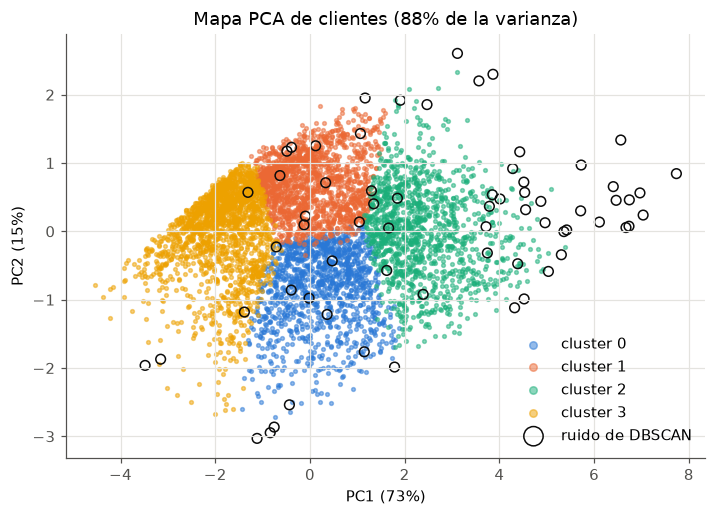

In [61]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
coords = pca.transform(X)
ratio = pca.explained_variance_ratio_
print(f"Varianza conservada: PC1 {ratio[0]:.1%} + PC2 {ratio[1]:.1%} = {ratio.sum():.1%}")

# Código de la figura (no hace falta entenderlo para seguir la clase).
atipico = customers["atipico"].to_numpy()
fig, ax = plt.subplots(figsize=(7.5, 5))
for k in range(4):
    mask = (customers["cluster"].to_numpy() == k) & ~atipico
    ax.scatter(coords[mask, 0], coords[mask, 1], s=6, alpha=0.5, color=COLORES[k],
               label=f"cluster {k}")
ax.scatter(coords[atipico, 0], coords[atipico, 1], s=40, facecolors="none",
           edgecolors="#0b0b0b", linewidths=1, label="ruido de DBSCAN")
ax.set(title=f"Mapa PCA de clientes ({ratio.sum():.0%} de la varianza)",
       xlabel=f"PC1 ({ratio[0]:.0%})", ylabel=f"PC2 ({ratio[1]:.0%})")
ax.legend(frameon=False, markerscale=2)
plt.show()

El mapa conserva el 88,4 % de la varianza. De izquierda a derecha crece la
intensidad de la relación con el comercio; los cuatro grupos son zonas
contiguas de una misma nube (por eso DBSCAN no los separaba) y la mayoría de
los atípicos está en el borde derecho, el de los grandes clientes.

**De cluster a segmento.** Un número de cluster no le dice nada a marketing.
Un **segmento** tiene un **nombre neutral**, que describe el comportamiento
sin juzgar a las personas, a partir del perfil de la parte 3. Ojo: la
correspondencia número → nombre vale para esta semilla; con otra, los
números cambiarían y habría que nombrar los grupos mirando el perfil.

Y cada atípico recibe un **motivo**, su rasgo más llamativo comparado con la
mediana de todos los clientes. `np.select(condiciones, motivos, default=...)`
asigna a cada fila el motivo de la **primera** condición que se cumple (por
eso "devolución masiva" va primero: un pedido anulado no es un gran cliente
aunque su gasto bruto lo parezca). Las dos cosas están dadas:

In [62]:
NOMBRES_SEGMENTO = {
    2: "Núcleo activo",
    0: "Recientes de baja frecuencia",
    1: "Habituales en pausa",
    3: "Compra única antigua",
}

mediana = customers[VARIABLES].median()
atipicos["motivo"] = np.select(
    [atipicos["return_share"] > 0.5,
     atipicos["monetary"] > 20 * mediana["monetary"],
     atipicos["n_products"] > 10 * mediana["n_products"],
     atipicos["frequency"] > 10 * mediana["frequency"]],
    ["devolución masiva", "gasto extremo", "catálogo muy amplio", "frecuencia extrema"],
    default="combinación poco habitual",
)
atipicos["motivo"].value_counts()

motivo
gasto extremo                40
combinación poco habitual    19
devolución masiva             5
catálogo muy amplio           2
frecuencia extrema            1
Name: count, dtype: int64

### Ejercicio 6 · La tabla de segmentos · completar código + interpretar

(a) Completa las dos columnas nuevas de `customers`: el nombre del segmento
de cada cliente (traduce `cluster` con el diccionario `NOMBRES_SEGMENTO`) y
el motivo de atípico, que debe quedar nulo en los clientes que no lo son.
Pistas:

```python
# .map(diccionario) traduce cada valor de una columna con el diccionario.
# Asignar una Serie a una columna alinea por índice: los clientes que no están quedan nulos.
```

In [64]:
# TU CÓDIGO
customers["segmento"] = customers["cluster"].map(NOMBRES_SEGMENTO)  # TODO: nombre del segmento de cada cliente
customers["motivo_atipico"] = atipicos["motivo"]  # TODO: motivo de atípico (nulo si no lo es)
customers[["cluster", "segmento", "atipico", "motivo_atipico"]].head()

,cluster,segmento,atipico,motivo_atipico
customer_id,,,,
12346,1,Habituales en pausa,True,devolución masiva
12347,2,Núcleo activo,False,NaN
12348,1,Habituales en pausa,False,NaN
12349,0,Recientes de baja frecuencia,False,NaN
12350,3,Compra única antigua,False,NaN


In [65]:
# Celda de rescate: cambia False por True solo si no has resuelto el apartado (a).
USAR_RESCATE = False
if USAR_RESCATE:
    referencia = pd.read_parquet("customers_segments_referencia.parquet")
    customers["segmento"] = referencia["segmento"]
    customers["motivo_atipico"] = referencia["motivo_atipico"]
    print("Rescate cargado: customers['segmento'] y customers['motivo_atipico'] de referencia")

(b) La celda dada ordena las columnas como en la tabla de referencia, guarda
el entregable `salidas/customers_segments.parquet` y lo compara con la tabla
de referencia. Si la comparación falla, el mensaje (en inglés) indica la
columna que difiere, por ejemplo `column name="segmento"`: empieza a revisar
por esa.

In [66]:
COLUMNAS_SEGMENTOS = ["country", "recency_days", "frequency", "monetary", "avg_ticket",
                      "n_products", "tenure_days", "n_return_invoices", "return_amount",
                      "has_returns", "return_share", "cluster", "segmento", "atipico",
                      "motivo_atipico"]
customers = customers[COLUMNAS_SEGMENTOS]
customers["cluster"] = customers["cluster"].astype("int64")   # K-means devuelve int32
customers.to_parquet(DIR_SALIDAS / "customers_segments.parquet")

# Comprobación
referencia = pd.read_parquet("customers_segments_referencia.parquet")
pd.testing.assert_frame_equal(customers, referencia)
print("✔ Correcto: tu tabla de segmentos es idéntica a la de referencia")

✔ Correcto: tu tabla de segmentos es idéntica a la de referencia


La ficha de cada segmento, con `perfilar` agrupando ya por nombre (y sin los
atípicos, para que unos pocos clientes extremos no muevan las cifras):

In [67]:
perfilar(customers[~customers["atipico"]], "segmento", VARIABLES).sort_values("pct_gasto", ascending=False)

,clientes,recency_days,frequency,monetary,n_products,pct_clientes,pct_gasto
segmento,,,,,,,
Núcleo activo,1225,20.00,12.00,"4,525.99",174.00,21.20,67.10
Habituales en pausa,1500,241.00,4.00,"1,169.64",61.00,25.90,18.60
Recientes de baja frecuencia,1226,24.00,3.00,805.31,45.00,21.20,9.90
Compra única antigua,1834,394.00,1.00,237.83,14.00,31.70,4.40


Pregunta: un compañero propone borrar los 67 atípicos "para que los
segmentos queden limpios". ¿Qué le contestas, con cifras?

**Tu respuesta:**

## 6. Chuleta y síntesis

### Chuleta de scikit-learn de esta clase

| Objeto | Para qué | Crear | Resultados tras `fit` | Aplicar a datos |
| --- | --- | --- | --- | --- |
| `StandardScaler` | Media 0 y desviación 1 por columna | `StandardScaler()` | `mean_`, `scale_` | `transform`, `fit_transform`, `inverse_transform` |
| `KMeans` | K grupos con centro | `KMeans(n_clusters=K, n_init=10, random_state=SEMILLA)` | `labels_`, `cluster_centers_`, `inertia_` | `predict`, `fit_predict` |
| `DBSCAN` | Grupos por densidad y ruido (−1) | `DBSCAN(eps=0.8, min_samples=8)` | `labels_`, `core_sample_indices_` | `fit_predict` (sin `predict`) |
| `NearestNeighbors` | Distancias a los vecinos (orientar `eps`) | `NearestNeighbors(n_neighbors=8)` | — | `kneighbors(X)` → (distancias, posiciones) |
| `PCA` | Resumir en 2 ejes para dibujar | `PCA(n_components=2, random_state=SEMILLA)` | `explained_variance_ratio_` | `transform`, `fit_transform` |
| `silhouette_score` | Calidad de una partición (−1 a 1) | Es una función: `silhouette_score(X, etiquetas)` | — | — |

**Errores frecuentes:**

- Agrupar sin escalar: la variable con números más grandes decide los grupos.
- Usar `fit_transform` con datos nuevos: se usa `transform`, con la regla
  aprendida de los datos originales.
- Leer `cluster_centers_` como si estuvieran en unidades originales: están en
  la escala de `X`.
- Dar significado a los números de cluster: son etiquetas arbitrarias; lo
  que importa es el perfil.
- Olvidar `random_state`: cada ejecución daría grupos algo distintos.
- Borrar los atípicos sin mirarlos: unos son errores, otros los mejores
  clientes.

### La petición de la directora

Responde en una o dos líneas a cada parte: ¿qué grupos le propones y qué
clientes no encajan en ninguno?

**Tu respuesta:**

### Lo que viene

Hoy no había etiquetas: nadie sabía a qué grupo pertenecía cada cliente. En
las próximas clases sí habrá una respuesta conocida (si una reseña es
positiva, si un cliente abandona...), pero el patrón de scikit-learn será el
mismo: crear, `fit`, leer los atributos con guion bajo y `predict`.